In [18]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

from pathlib import Path

# Import modules
from datetime import datetime
import cma
from IPython.display import display
import lumapi as lma
import math
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [19]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                   | Description                                               | Example                                                           |
| :-------------------------- | :-------------------------------------------------------- | :---------------------------------------------------------------- |
| **wavelength_center**       | Wavelength for which simulation will be done.             | `1.55*um`                                                         |
| **wavelength_span**         | Span of the wavelength for which simulation will be done. | `0.14*um`                                                         |
| **dc_sparams**              | S-parameters of examined directional coupler.             | `results/si3n4_w1000nm_h360nm_directCoupler_g400nm_l12um_man.dat` |

In [20]:
# Si3N4/SiO2 1000x360nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

dc_sparams = "/workspace/Sparameters/si3n4_w1000nm_h360nm_directCoupler_g400nm_l12um_man.dat"


In [21]:
calc_freq = lambda wvl: (C/wvl)
calc_mw = lambda dbm: 10.0 ** (dbm / 10.0)

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

In [22]:
wavelength_min = wavelength_center - wavelength_span/2
wavelength_max = wavelength_center + wavelength_span/2

frequency_center = calc_freq(wavelength_center)
frequency_min = calc_freq(wavelength_max)
frequency_max = calc_freq(wavelength_min)
frequency_span = frequency_max - frequency_min

ic_cell_size = 175

In [23]:
solver = lma.INTERCONNECT(hide=False)

# Ideal Directional Coupler

In [24]:
# Circuit setup

solver.switchtodesign()
solver.deleteall()

# Optical Network Analyzer
solver.addelement(
    "Optical Network Analyzer",
    name="ONA-1",
    input_parameter="center and range",
    number_of_input_ports=2,
    center_frequency=frequency_center,
    frequency_range=frequency_span,
    x_position=0,
    y_position=-1*ic_cell_size,
)

# Directional Coupler
solver.addelement(
    "Waveguide coupler",
    name="DC-1",
    x_position=0,
    y_position=1*ic_cell_size,
)

# Connections
solver.connect("ONA-1", "output", "DC-1", "port 1")
solver.connect("DC-1", "port 3", "ONA-1", "input 1")
solver.connect("DC-1", "port 4", "ONA-1", "input 2")

1.0

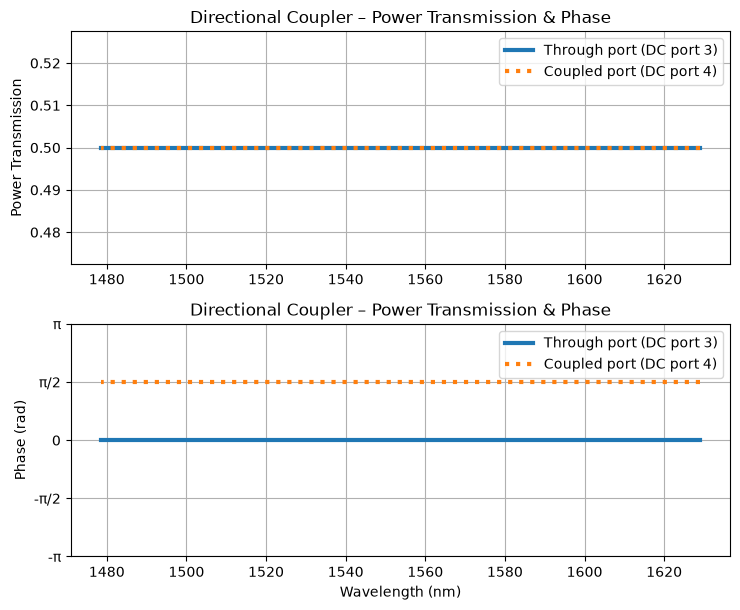

In [25]:
# Simulation

solver.switchtodesign()
solver.run()

# Retrieve ONA results
T1 = solver.getresult("ONA-1", "input 1/mode 1/transmission")
wavelengths = np.squeeze(T1["wavelength"])
T1 = np.squeeze(T1["TE transmission"])
P1 = solver.getresult("ONA-1", "input 1/mode 1/angle")
P1 = np.squeeze(P1["TE angle (rad)"])

T2 = solver.getresult("ONA-1", "input 2/mode 1/transmission")
T2 = np.squeeze(T2["TE transmission"])

P2 = solver.getresult("ONA-1", "input 2/mode 1/angle")
P2 = np.squeeze(P2["TE angle (rad)"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6.2))

ax1.plot(wavelengths * 1e9, np.abs(T1)**2,
         label="Through port (DC port 3)",
         linestyle="-", linewidth=3)

ax1.plot(wavelengths * 1e9, np.abs(T2)**2,
         label="Coupled port (DC port 4)",
         linestyle=":", linewidth=3)

ax1.set_ylabel("Power Transmission")
ax1.set_title("Directional Coupler – Power Transmission & Phase")
ax1.grid(True)
ax1.legend()

ax2.plot(wavelengths * 1e9, P1,
         label="Through port (DC port 3)",
         linestyle="-", linewidth=3)

ax2.plot(wavelengths * 1e9, P2,
         label="Coupled port (DC port 4)",
         linestyle=":", linewidth=3)

ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("Phase (rad)")
ax2.set_yticks([-np.pi, -np.pi / 2, 0.0, np.pi / 2, np.pi])
ax2.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])
ax2.set_title("Directional Coupler – Power Transmission & Phase")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Directional coupler based on S-parameters

In [26]:
# Circuit setup

solver.switchtodesign()
solver.deleteall()

# Optical Network Analyzer
solver.addelement(
    "Optical Network Analyzer",
    name="ONA-1",
    input_parameter="center and range",
    number_of_input_ports=2,
    center_frequency=frequency_center,
    frequency_range=frequency_span,
    x_position=0,
    y_position=-1*ic_cell_size,
)

# Directional Coupler
print(dc_sparams)
solver.addelement(
    "Optical N Port S-Parameter",
    name="DC-1",
    x_position=0,
    y_position=1*ic_cell_size,
    load_from_file=True,
    s_parameters_filename=dc_sparams,
)

# Connections
solver.connect("ONA-1", "output", "DC-1", "port 1")
solver.connect("DC-1", "port 3", "ONA-1", "input 1")
solver.connect("DC-1", "port 4", "ONA-1", "input 2")

/workspace/Sparameters/si3n4_w1000nm_h360nm_directCoupler_g400nm_l12um_man.dat


1.0

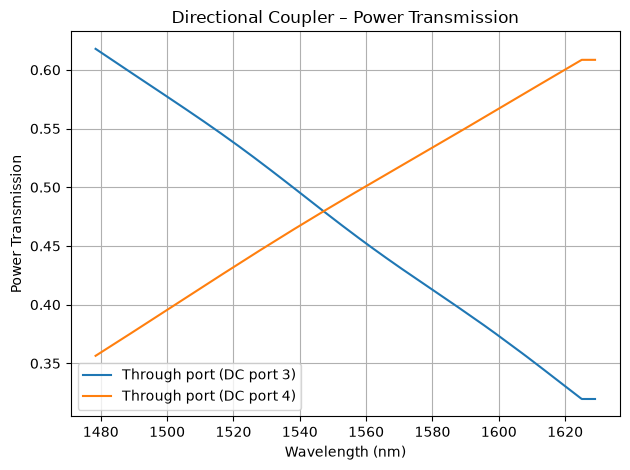

In [27]:
# Simulation

solver.switchtodesign()
solver.run()

# Retrieve ONA results
T1 = solver.getresult("ONA-1", "input 1/mode 1/transmission")
T2 = solver.getresult("ONA-1", "input 2/mode 1/transmission")
wavelengths = np.squeeze(T1["wavelength"])
T1 = np.squeeze(T1["mode 1 transmission"])
T2 = np.squeeze(T2["mode 1 transmission"])

plt.plot(
    wavelengths * 1e9, 
    np.abs(T1)**2,     
    label="Through port (DC port 3)",
)

plt.plot(
    wavelengths * 1e9, 
    np.abs(T2)**2,     
    label="Through port (DC port 4)",
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Power Transmission")
plt.title("Directional Coupler – Power Transmission")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Logic unit

In [28]:
# Circuit setup

solver.switchtodesign()
solver.deleteall()

def add_logic_unit(name, x, y, idealized_dc=False):
    if idealized_dc:
        solver.addelement(
            "Waveguide coupler",
            name=f"{name}-DC1",
            conjugate=True,
            x_position=x,
            y_position=y,
        )

        solver.addelement(
            "Waveguide coupler",
            name=f"{name}-DC2",
            conjugate=True,
            x_position=x + 1.6*ic_cell_size,
            y_position=y,
        )
    else:
        solver.addelement(
            "Optical N Port S-Parameter",
            name=f"{name}-DC1",
            x_position=x,
            y_position=y,
            load_from_file=True,
            s_parameters_filename=dc_sparams,
        )

        solver.addelement(
            "Optical N Port S-Parameter",
            name=f"{name}-DC2",
            x_position=x + 1.6*ic_cell_size,
            y_position=y,
            load_from_file=True,
            s_parameters_filename=dc_sparams,
        )

    solver.addelement(
        "Optical Phase Shift",
        name=f"{name}-PS1",
        x_position=x + 0.8*ic_cell_size,
        y_position=y,
    )

    solver.addelement(
        "Optical Phase Shift",
        name=f"{name}-PS2",
        x_position=x + 2.4*ic_cell_size,
        y_position=y,
    )

    solver.connect(f"{name}-DC1", "port 3", f"{name}-PS1", "port 1")
    solver.connect(f"{name}-PS1", "port 2", f"{name}-DC2", "port 1")
    solver.connect(f"{name}-DC1", "port 4", f"{name}-DC2", "port 2")

    solver.connect(f"{name}-DC2", "port 3", f"{name}-PS2", "port 1")

solver.addelement(
    "Waveguide Y Branch",
    name="Y1",
    x_position=-2*ic_cell_size,
    y_position=0*ic_cell_size,
)

solver.addelement(
    "Waveguide Y Branch",
    name="Y2",
    x_position=-1*ic_cell_size,
    y_position=-0.5*ic_cell_size,
)

solver.addelement(
    "Waveguide Y Branch",
    name="Y3",
    x_position=-1*ic_cell_size,
    y_position=0.5*ic_cell_size,
)

solver.addelement(
    "Optical Attenuator",
    name="A1",
    x_position=0*ic_cell_size,
    y_position=-0.75*ic_cell_size,
)

solver.addelement(
    "Optical Attenuator",
    name="A2",
    x_position=0*ic_cell_size,
    y_position=-0.25*ic_cell_size,
)

solver.addelement(
    "Optical Attenuator",
    name="A3",
    x_position=0*ic_cell_size,
    y_position=0.25*ic_cell_size,
)

add_logic_unit(
    "L1",
    x = 1*ic_cell_size,
    y = -0.5*ic_cell_size,
)

add_logic_unit(
    "L2",
    x = 3.5*ic_cell_size,
    y = 0.5*ic_cell_size,
)

add_logic_unit(
    "L3",
    x = 7*ic_cell_size,
    y = -0.5*ic_cell_size,
)

# Optical Network Analyzer
solver.addelement(
    "Optical Network Analyzer",
    name="ONA1",
    input_parameter="center and range",
    number_of_input_ports=1,
    center_frequency=frequency_center,
    frequency_range=frequency_span,
    x_position=0,
    y_position=-2*ic_cell_size,
)

solver.connect("ONA1", "output", "Y1", "port 1")

solver.connect("Y1", "port 2", "Y2", "port 1")
solver.connect("Y1", "port 3", "Y3", "port 1")

solver.connect("Y2", "port 2", "A1", "port 1")
solver.connect("Y2", "port 3", "A2", "port 1")
solver.connect("Y3", "port 2", "A3", "port 1")

solver.connect("A1", "port 2", "L1-DC1", "port 1")
solver.connect("A2", "port 2", "L1-DC1", "port 2")
solver.connect("A3", "port 2", "L2-DC1", "port 2")

solver.connect("L1-PS2", "port 2", "L3-DC1", "port 1")
solver.connect("L1-DC2", "port 4", "L2-DC1", "port 1")
solver.connect("L2-PS2", "port 2", "L3-DC1", "port 2")

solver.connect("L3-PS2", "port 2", "ONA1", "input 1")
# solver.connect("L3-DC2", "port 4", "ONA1", "input 2")
# solver.connect("L2-DC2", "port 4", "ONA1", "input 3")

def set_input(i, off_db=100.0, on_db=0.0):
  att_a = on_db if i[0] else off_db
  att_b = on_db if i[1] else off_db
  att_c = on_db if i[2] else off_db

  solver.setnamed("A1", "attenuation", float(att_a))
  solver.setnamed("A2", "attenuation", float(att_b))
  solver.setnamed("A3", "attenuation", float(att_c))

def set_phase(p):
    t1, p1, t2, p2, t3, p3 = p
    solver.setnamed("L1-PS1", "phase shift", t1)
    solver.setnamed("L1-PS2", "phase shift", p1)

    solver.setnamed("L2-PS1", "phase shift", t2)
    solver.setnamed("L2-PS2", "phase shift", p2)

    solver.setnamed("L3-PS1", "phase shift", t3)
    solver.setnamed("L3-PS2", "phase shift", p3)


In [29]:
solver.switchtodesign()

cases = [
# A | B | C | Y
    (0, 0, 1, 0),
    (0, 1, 1, 0),
    (1, 0, 1, 0),
    (1, 1, 1, 1),
]

p = [ 1.57, -1.88, -0.01, -1.08, -2.44,  0.  ]
set_phase(p)

for a,b,c,o in cases:
    solver.switchtodesign()
    i = (a,b,c)
    set_input(i)
    solver.run()
    T1 = solver.getresult("ONA1", "input 1/mode 1/transmission")
    wavelengths = np.squeeze(T1["wavelength"])
    T1 = np.squeeze(T1["TE transmission"])
    Y = np.abs(T1)**2

    print(f"  A={a}, B={b}, C={c} | target o={o} | {np.max(Y)}")

  A=0, B=0, C=1 | target o=0 | 0.025591412196455925
  A=0, B=1, C=1 | target o=0 | 0.03299850263390673
  A=1, B=0, C=1 | target o=0 | 0.04152980336020055
  A=1, B=1, C=1 | target o=1 | 0.2338153284578473
